Imports

In [35]:
from pathlib import Path

from typing import Any
import requests 
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statistics import mean, median



Reading our client ID's from local files exisiting outside of the repository.

In [36]:
id_file = Path.home() / "frost_client_id.txt"
client_id = id_file.read_text().strip()

Requesting the daily mean air temperatures for all of 2025.
We used the code prompt given to us in task 1 in the deliverable.

In [37]:
endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
}


def get_observations(
        endpoint: str,
        parameters: dict[str, str],
        client_id: str, 
) -> list[dict[str, Any]]:
    """Collecting the observations from Frost

    Args:
        endpoint: the URL of the Frost observation endpoint.
        parameters: Filters the station
        client_id: ID used to verify and authenticate the request.

    Returns:
        A list of observations from Frost.
    """

    response = requests.get(
        endpoint,
        params=parameters, 
        auth=(client_id, ""),
        timeout=30,
    )
    response.raise_for_status()
    return response.json()["data"]

data = get_observations(endpoint, parameters, client_id)

print(f"Retrieved {len(data)} observation records from Frost.")
if data:
    print(data[0])

Retrieved 365 observation records from Frost.
{'sourceId': 'SN17850:0', 'referenceTime': '2025-01-01T00:00:00.000Z', 'observations': [{'elementId': 'mean(air_temperature P1D)', 'value': -5.2, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}, {'elementId': 'mean(air_temperature P1D)', 'value': -2.8, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT6H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1'}]}


Plotting and making summary table.

In [38]:
def get_temperatures(
    data: list[dict[str, Any]],
) -> tuple[list[datetime], list[float]]:
    """Getting the dates and temperatures from the observations."""
    dates: list[datetime] = []
    temperatures: list[float] = []

    for record in sorted(data, key=lambda record: record["referenceTime"]):
        date = datetime.strptime(record["referenceTime"][:10], "%Y-%m-%d")

        for observation in record["observations"]:
            if observation["elementId"] == "mean(air_temperature P1D)":
                dates.append(date)
                temperatures.append(float(observation["value"]))

    return dates, temperatures


In [39]:
def plot_temperatures(
    dates: list[datetime],
    temperatures: list[float],
) -> None:
    """Plotting the mean air temperatures for Ås in 2025"""
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(dates, temperatures, color="blue", linewidth=1)
    ax.set_title("Daily Mean Air Temperature in Ås, 2025")
    ax.set_xlabel("Month")
    ax.set_ylabel("Temperature (°C)")

    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

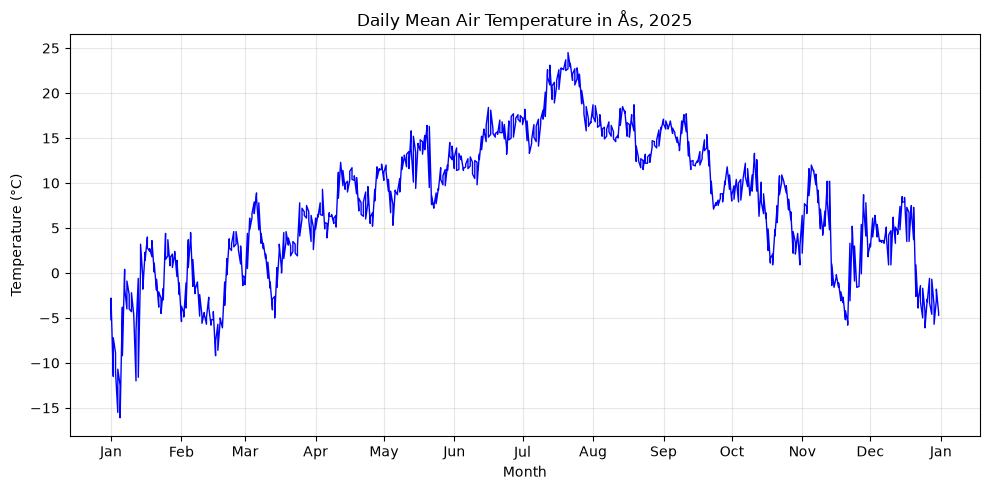

In [40]:
dates, temperatures = get_temperatures(data)
plot_temperatures(dates, temperatures)

In [41]:
def print_temperature_summary(temperatures: list[float]) -> None:
    """Printing the summary statistics for daily mean air tempertaures"""
    summary: dict[str, float] = {
        "Mean": mean(temperatures),
        "Minimum": min(temperatures),
        "Maximum": max(temperatures),
        "Median": median(temperatures),
    }

    print("Daily mean air tempertaures in Ås, 2025")
    print(f"{'Statistic':<12} {'Value':>12}")
    print("-" * 25)

    for statistic, value in summary.items():
        print(f"{statistic:<12} {value:>12.2f}")

In [42]:
print_temperature_summary(temperatures)

Daily mean air tempertaures in Ås, 2025
Statistic           Value
-------------------------
Mean                 7.87
Minimum            -16.10
Maximum             24.50
Median               8.30
